Experiment 1: Does our validation strategy give trustworthy estimates?

In [1]:
import pandas as pd

In [2]:
df = pd.read_csv("../data/clean/train.csv")
df["Date"] = pd.to_datetime(df["Date"])

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 844392 entries, 0 to 844391
Data columns (total 9 columns):
 #   Column         Non-Null Count   Dtype         
---  ------         --------------   -----         
 0   Store          844392 non-null  int64         
 1   DayOfWeek      844392 non-null  int64         
 2   Date           844392 non-null  datetime64[us]
 3   Sales          844392 non-null  int64         
 4   Customers      844392 non-null  int64         
 5   Open           844392 non-null  int64         
 6   Promo          844392 non-null  int64         
 7   StateHoliday   844392 non-null  str           
 8   SchoolHoliday  844392 non-null  int64         
dtypes: datetime64[us](1), int64(7), str(1)
memory usage: 58.0 MB


In [3]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
Store,844392.0,558.42292,1.0,280.0,558.0,837.0,1115.0,321.731914
DayOfWeek,844392.0,3.520361,1.0,2.0,3.0,5.0,7.0,1.723689
Date,844392,2014-04-11 01:02:42.487564,2013-01-01 00:00:00,2013-08-16 00:00:00,2014-03-31 00:00:00,2014-12-10 00:00:00,2015-07-31 00:00:00,NaN
Sales,844392.0,6955.514291,0.0,4859.0,6369.0,8360.0,41551.0,3104.21468
Customers,844392.0,762.728395,0.0,519.0,676.0,893.0,7388.0,401.227674
Open,844392.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0
Promo,844392.0,0.446352,0.0,0.0,0.0,1.0,1.0,0.497114
SchoolHoliday,844392.0,0.19358,0.0,0.0,0.0,0.0,1.0,0.395103


In [4]:
test = pd.read_csv("../data/test.csv")
test = test.drop(columns=["Open"])

test["Date"] = pd.to_datetime(test["Date"])
test.info()

<class 'pandas.DataFrame'>
RangeIndex: 41088 entries, 0 to 41087
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Id             41088 non-null  int64         
 1   Store          41088 non-null  int64         
 2   DayOfWeek      41088 non-null  int64         
 3   Date           41088 non-null  datetime64[us]
 4   Promo          41088 non-null  int64         
 5   StateHoliday   41088 non-null  str           
 6   SchoolHoliday  41088 non-null  int64         
dtypes: datetime64[us](1), int64(5), str(1)
memory usage: 2.2 MB


In [5]:
test.describe().T

,count,mean,min,25%,50%,75%,max,std
Id,41088.0,20544.5,1.0,10272.75,20544.5,30816.25,41088.0,11861.228267
Store,41088.0,555.899533,1.0,279.75,553.5,832.25,1115.0,320.274496
DayOfWeek,41088.0,3.979167,1.0,2.0,4.0,6.0,7.0,2.015481
Date,41088,2015-08-24 12:00:00,2015-08-01 00:00:00,2015-08-12 18:00:00,2015-08-24 12:00:00,2015-09-05 06:00:00,2015-09-17 00:00:00,NaN
Promo,41088.0,0.395833,0.0,0.0,0.0,1.0,1.0,0.489035
SchoolHoliday,41088.0,0.443487,0.0,0.0,0.0,1.0,1.0,0.496802


In [6]:
df.head()

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1
4,5,5,2015-07-31,4822,559,1,1,0,1


In [7]:
df['Open'].unique()
# drop it
df.drop(columns=["Open"], inplace=True)
df.columns

C:\Users\ecole\AppData\Local\Temp\ipykernel_31892\1618845791.py:3: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns=["Open"], inplace=True)


Index(['Store', 'DayOfWeek', 'Date', 'Sales', 'Customers', 'Promo',
       'StateHoliday', 'SchoolHoliday'],
      dtype='str')

## Forecast-origin and target-label construction.


In [8]:
df.head(3)

,Store,DayOfWeek,Date,Sales,Customers,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,0,1
1,2,5,2015-07-31,6064,625,1,0,1
2,3,5,2015-07-31,8314,821,1,0,1


In [9]:
df.columns

Index(['Store', 'DayOfWeek', 'Date', 'Sales', 'Customers', 'Promo',
       'StateHoliday', 'SchoolHoliday'],
      dtype='str')

In [10]:

# 1. sort bystore, and order Date chronically
df = df.sort_values(by=["Store", "Date"], ascending=[True, True])
df.head()

,Store,DayOfWeek,Date,Sales,Customers,Promo,StateHoliday,SchoolHoliday
843264,1,3,2013-01-02,5530,668,0,0,1
842155,1,4,2013-01-03,4327,578,0,0,1
841047,1,5,2013-01-04,4486,619,0,0,1
839940,1,6,2013-01-05,4997,635,0,0,1
838815,1,1,2013-01-07,7176,785,1,0,1


In [11]:
df.tail()

,Store,DayOfWeek,Date,Sales,Customers,Promo,StateHoliday,SchoolHoliday
5564,1115,1,2015-07-27,10712,608,1,0,1
4451,1115,2,2015-07-28,8093,500,1,0,1
3338,1115,3,2015-07-29,7661,473,1,0,1
2225,1115,4,2015-07-30,8405,502,1,0,1
1112,1115,5,2015-07-31,8680,538,1,0,1


In [12]:
assert not df.duplicated(['Store', 'Date']).any()

In [13]:
# 2. generate forcast origins
# for each store, i consider each date a potential forcast origin
# only valid if it has

origin_df = df[["Store", "Date"]].copy()
origin_df = origin_df.rename(columns={"Date": "origin_date"})
origin_df.head()

,Store,origin_date
843264,1,2013-01-02
842155,1,2013-01-03
841047,1,2013-01-04
839940,1,2013-01-05
838815,1,2013-01-07


In [14]:
# 3. generate target dates for each horizon

training_rows = []
horizons = [1, 7, 14, 21, 28]

for horizon in horizons:
    temp = origin_df.copy()

    temp['forcast_horizon'] = horizon
    temp["target_date"] = temp["origin_date"] + pd.Timedelta(days=horizon)
    
    training_rows.append(temp)

forcast_df = pd.concat(training_rows, ignore_index=True)
forcast_df.head()

,Store,origin_date,forcast_horizon,target_date
0,1,2013-01-02,1,2013-01-03
1,1,2013-01-03,1,2013-01-04
2,1,2013-01-04,1,2013-01-05
3,1,2013-01-05,1,2013-01-06
4,1,2013-01-07,1,2013-01-08


In [15]:
forcast_df.loc[forcast_df['forcast_horizon'] == 7]

,Store,origin_date,forcast_horizon,target_date
844392,1,2013-01-02,7,2013-01-09
844393,1,2013-01-03,7,2013-01-10
844394,1,2013-01-04,7,2013-01-11
844395,1,2013-01-05,7,2013-01-12
844396,1,2013-01-07,7,2013-01-14
...,...,...,...,...
1688779,1115,2015-07-27,7,2015-08-03
1688780,1115,2015-07-28,7,2015-08-04
1688781,1115,2015-07-29,7,2015-08-05
1688782,1115,2015-07-30,7,2015-08-06


In [16]:
forcast_df.shape

(4221960, 4)

In [17]:
origin_df.head()

,Store,origin_date
843264,1,2013-01-02
842155,1,2013-01-03
841047,1,2013-01-04
839940,1,2013-01-05
838815,1,2013-01-07


In [18]:
origin_df.shape

(844392, 2)

horizon length=5
origion length = 844,392
training rows should be
844,392 * 5 = 4,221,960

forcast_df is correct in length
for each horizon:
    for each store forcast_horizon = horizon(e.g 1)
    repeat for each date in a store
    like store 1 across all date set forcat_horizon = horizon(e.g 1)
    when all date has finish
    duplicate store 1 across all date again this time set forcat_horizon = the next horizon(e.g 7)
    until all horizon finish


In [19]:
# 4th step to be continued...

In [20]:
forcast_df.head()

,Store,origin_date,forcast_horizon,target_date
0,1,2013-01-02,1,2013-01-03
1,1,2013-01-03,1,2013-01-04
2,1,2013-01-04,1,2013-01-05
3,1,2013-01-05,1,2013-01-06
4,1,2013-01-07,1,2013-01-08


In [21]:
forcast_df['target_date'].duplicated().any()
# True. okay fair, different stores can have same origin date thus targeting same target_date

np.True_

In [22]:
forcast_df.loc[forcast_df['target_date'].duplicated(keep=False)].sort_values('target_date')

,Store,origin_date,forcast_horizon,target_date
515314,682,2013-01-01,1,2013-01-02
400916,530,2013-01-01,1,2013-01-02
387281,512,2013-01-01,1,2013-01-02
194139,259,2013-01-01,1,2013-01-02
425029,562,2013-01-01,1,2013-01-02
...,...,...,...,...
3713731,444,2015-07-31,28,2015-08-28
4185343,1067,2015-07-31,28,2015-08-28
3712954,443,2015-07-31,28,2015-08-28
3719188,451,2015-07-31,28,2015-08-28


In [23]:
forcast_df.duplicated(subset=['Store', 'target_date']).any()

np.True_

In [24]:
forcast_df.loc[
    forcast_df.duplicated(subset=["Store", "target_date"], keep=False)
].sort_values(['Store', 'target_date']).head(15)

,Store,origin_date,forcast_horizon,target_date
5,1,2013-01-08,1,2013-01-09
844392,1,2013-01-02,7,2013-01-09
6,1,2013-01-09,1,2013-01-10
844393,1,2013-01-03,7,2013-01-10
7,1,2013-01-10,1,2013-01-11
844394,1,2013-01-04,7,2013-01-11
8,1,2013-01-11,1,2013-01-12
844395,1,2013-01-05,7,2013-01-12
10,1,2013-01-14,1,2013-01-15
844397,1,2013-01-08,7,2013-01-15


- After checking for duplicate `target_date` values, I checked for duplicates using both `Store` and `target_date`.
- Found duplicate combinations.
- Looking at the rows, the same store can have multiple forecasts targeting the same date, but generated from different origin dates and forecast horizons.
- For example, Store 1 has two forecasts targeting 2013-01-09:
  - Origin date: 2013-01-08, forecast horizon: 1
  - Origin date: 2013-01-02, forecast horizon: 7

This is expected because the same target date can be forecast from different points in time. These are different forecasting origins, not necessarily duplicate records.

A unique forcast obseration is identified by:
`Store + origin_date + forecast_horizon`

In [25]:
forcast_df.shape

(4221960, 4)

In [26]:
# 4. lookup the actual target sales
sales_lookup = df[["Store", "Date", "Sales"]].rename(
    columns={"Date": "target_date", "Sales": "target_sales"}
)

forcast_df = forcast_df.merge(
    sales_lookup,
    on=["Store", "target_date"],
    how="left",
    validate="many_to_one",  # many rows from forcast all map to 1 sales_lookup target_date
)
forcast_df.head()

,Store,origin_date,forcast_horizon,target_date,target_sales
0,1,2013-01-02,1,2013-01-03,4327.0
1,1,2013-01-03,1,2013-01-04,4486.0
2,1,2013-01-04,1,2013-01-05,4997.0
3,1,2013-01-05,1,2013-01-06,NaN
4,1,2013-01-07,1,2013-01-08,5580.0


In [27]:
df.loc[df['Store']==1].head(7)

,Store,DayOfWeek,Date,Sales,Customers,Promo,StateHoliday,SchoolHoliday
843264,1,3,2013-01-02,5530,668,0,0,1
842155,1,4,2013-01-03,4327,578,0,0,1
841047,1,5,2013-01-04,4486,619,0,0,1
839940,1,6,2013-01-05,4997,635,0,0,1
838815,1,1,2013-01-07,7176,785,1,0,1
837710,1,2,2013-01-08,5580,654,1,0,1
836605,1,3,2013-01-09,5471,626,1,0,1


In [28]:
forcast_df.isna().sum()

Store                   0
origin_date             0
forcast_horizon         0
target_date             0
target_sales       350134
dtype: int64

yes, some Store don't have a recorded sale for some target date
what to do?
i don't think i should treat it as missing value and impute with something
becasue truely there is no record for it
solution:
remove invalide forcast origin


In [29]:

forcast_df.loc[forcast_df["origin_date"] == "2013-01-05"].sort_values(
    ["Store", 'forcast_horizon']
).head(15)

,Store,origin_date,forcast_horizon,target_date,target_sales
3,1,2013-01-05,1,2013-01-06,NaN
844395,1,2013-01-05,7,2013-01-12,4952.0
1688787,1,2013-01-05,14,2013-01-19,5182.0
2533179,1,2013-01-05,21,2013-01-26,5598.0
3377571,1,2013-01-05,28,2013-02-02,5970.0
784,2,2013-01-05,1,2013-01-06,NaN
845176,2,2013-01-05,7,2013-01-12,2630.0
1689568,2,2013-01-05,14,2013-01-19,2399.0
2533960,2,2013-01-05,21,2013-01-26,2205.0
3378352,2,2013-01-05,28,2013-02-02,2956.0


- group rows with same `Store` and `origin_date`
example:
```
Store 1, 2013-01-02
Store 1, 2013-01-02	
Store 1, 2013-01-05
```

- select `target_sales` and count
- For each group, count how many non-null `target_sales` values it contains.
- `transform()` returns a result(the count of `target_sales`) for every row
- sticking to the above example:
```
Store 1, 2013-01-02, `target_sales` count = 5
Store 1, 2013-01-02, `target_sales` count = 5
Store 1, 2013-01-05, `target_sales` count = 4
```

In [30]:
# keep only forcast origins with all 5 targets observations
# becasue we want to evaluate forecasts at horizons 1, 7, 14, 21 and 28, we need complete observations for all five horizons.

valid_origins = (
    forcast_df.groupby(['Store', 'origin_date'])['target_sales']
    .transform('count') == len(horizons)
)
valid_origins   

0           True
1           True
2           True
3          False
4           True
           ...  
4221955    False
4221956    False
4221957    False
4221958    False
4221959    False
Name: target_sales, Length: 4221960, dtype: bool

In [31]:
forcast_df = forcast_df[valid_origins].copy()

forcast_df = forcast_df.sort_values(
    ['Store', 'origin_date', 'forcast_horizon']
)
forcast_df.shape

(2808265, 5)

In [32]:
forcast_df.head(25)

,Store,origin_date,forcast_horizon,target_date,target_sales
0,1,2013-01-02,1,2013-01-03,4327.0
844392,1,2013-01-02,7,2013-01-09,5471.0
1688784,1,2013-01-02,14,2013-01-16,4008.0
2533176,1,2013-01-02,21,2013-01-23,5578.0
3377568,1,2013-01-02,28,2013-01-30,4601.0
1,1,2013-01-03,1,2013-01-04,4486.0
844393,1,2013-01-03,7,2013-01-10,4892.0
1688785,1,2013-01-03,14,2013-01-17,4044.0
2533177,1,2013-01-03,21,2013-01-24,5195.0
3377569,1,2013-01-03,28,2013-01-31,4709.0


In [33]:
# df.loc[df["Date"] == "2013-01-25" and df['Store'] == 1]
df.loc[df["Date"] == "2013-01-25"]
# store 1 sals on 2013-01-04 = 5586
# correct with forcast_df row index 2533178

,Store,DayOfWeek,Date,Sales,Customers,Promo,StateHoliday,SchoolHoliday
821081,1,5,2013-01-25,5586,676,1,0,0
821082,2,5,2013-01-25,4589,522,1,0,0
821083,3,5,2013-01-25,7565,773,1,0,0
821084,4,5,2013-01-25,9730,1409,1,0,0
821085,5,5,2013-01-25,4960,564,1,0,0
...,...,...,...,...,...,...,...,...
822184,1111,5,2013-01-25,5114,485,1,0,0
822185,1112,5,2013-01-25,13661,1064,1,0,0
822186,1113,5,2013-01-25,6714,778,1,0,0
822187,1114,5,2013-01-25,19446,2838,1,0,0


In [34]:
forcast_df.isna().sum()

Store              0
origin_date        0
forcast_horizon    0
target_date        0
target_sales       0
dtype: int64

In [35]:
# forcast_df.to_csv("../data/clean/train_forcast.csv", index=False)


A forecast origin is the date at which you stand and ask:
"What will sales be in the future?"

I use dates as forcast origin provded there is enough future data for the 5 horizon.

to avoid future leakage
I use only information available at forcast origin.

Important: Historical sales features such as lags must only use sales available at the forecast origin. Target-date calendar and promotion features are allowed only when those values are genuinely known in advance.

I am imagining this business makes a new forcast everyday.

Within each store valid forcast origin = t if t+28 <= available date


validation question is:

> How should I evaluate a four-week forecasting model to establish whether its predictions will remain reliable when predicting future harvests?

I decided to evaluate at 1, 7, 14, 21 and 28 days ahead.

To investigate how forecast accuracy changes with prediction horizon.

| Horizon | What you're evaluating         |
| ------- | ------------------------------ |
| 1 day   | Predicting tomorrow's sales    |
| 7 days  | Predicting sales 7 days ahead  |
| 14 days | Predicting sales 14 days ahead |
| 21 days | Predicting sales 21 days ahead |
| 28 days | Predicting sales 28 days ahead |



# Split Dataset

## 1. When to split the dataset

I will split the dataset before feature engineering, partly because I am considering using lag and rolling-window features.

I started by listing the available validation strategies I know and reasoning through which ones are appropriate for this experiment.

The split should not randomly shuffle or select data points. It should preserve the chronological order of the data.

I will therefore arrange the dataset chronologically before splitting it.

## 2. Validation strategies considered

The validation strategies I considered are:

1. Hold-out train-validation split
2. K-Fold cross-validation
   - Group K-Fold (`group=Store`)
   - Expanding-window (Walk-Forward) CV
   - Rolling-window CV
3. Out-of-Time (OOT) validation
   - Static holdout

### Why I ruled out some options

**Hold-out train-validation split**

This performs only one split. The model is evaluated on one validation period, so the result could be influenced by how that particular period behaves.

I want to evaluate the model across multiple future periods to understand how consistently it performs.

**Static OOT holdout**

This trains on a fixed historical period and evaluates on a later period. The split does not move.

It is similar to a chronological train-validation split, so using it alone would give me only one validation period.

I will still reserve a separate static OOT period for final evaluation, but I will not use it as my only validation strategy.

**Clarifying OOT validation**

OOT validation means evaluating a model on data that comes after its training data.

A static holdout, expanding-window CV, and rolling-window CV can all follow this principle. OOT is not a separate method that replaces expanding or rolling CV.

## 3. How I will split the data

My experiment asks:

> How should I evaluate a four-week forecasting model to establish whether its predictions will remain reliable when predicting future harvests?

I will use multiple temporal validation folds and reserve a final untouched static OOT test period.

I will first reserve the last 3 months of the training dataset for static OOT evaluation.

The remaining data will be used for temporal cross-validation.

## 4. Cross-validation strategies

### Group K-Fold

Group K-Fold tests whether the model can generalize to stores it has not seen during training.

That is not what this experiment is asking.

I already have historical data for the stores. The question is:

Can the model predict future sales accurately for stores whose historical data it has already observed?

I can include `Store` as a feature so the model can learn store-specific patterns.

### Expanding-window (Walk-Forward) CV

This tests whether incorporating more historical observations improves future predictions.

The training window grows with each fold. Earlier observations remain in the training data as newer observations are added.

### Rolling-window CV

This tests whether more recent observations are sufficient to produce reliable predictions.

The training window has a fixed size and moves forward with each fold. Older observations are dropped as newer observations are added.

## 5. What kind of generalization do I want to test?

I want to test **temporal generalization**.

The model already has historical observations from the stores. I want to understand whether it can use that historical information to make reliable predictions for future dates.

I also want to understand whether using more historical data or focusing on more recent data produces better results.

## 6. Validation rules and important considerations

**Evaluate all five forecast horizons in every fold.**

Each validation fold should evaluate:

- 1 day ahead
- 7 days ahead
- 14 days ahead
- 21 days ahead
- 28 days ahead

I will calculate performance separately for each horizon to understand how prediction accuracy changes as the forecast horizon increases.

**Training cutoff must respect both `origin_date` and `target_date`.**

At each fold's training cutoff, only training examples whose `target_date` is on or before that cutoff can be used.

Otherwise, the model would learn from outcomes that had not happened yet.

For example:

```python
train_df = train_df[
    train_df["target_date"] <= training_cutoff
]
```

For rolling-window CV, I must also restrict the training data to the selected rolling window. For expanding-window CV, I retain the earlier training history.

This is important because I cannot train a model on labels that were not available at the training cutoff.

- Training: target labels must be available by the training cutoff.
- Validation: target labels must exist in our historical dataset so we can compare predictions against actual sales later. They must be future outcomes relative to the forecast origin.

The validation target values are for evaluation, not model fitting.

**Initial training window**

I will start with a 12-month initial training window.

This gives the model an opportunity to observe a complete annual cycle before its first validation period.

**Overlapping forecast targets**

Since my forecasting origins are daily, different origins can have overlapping forecast targets.

For example, the 28-day forecast from one origin may target the same date as the 27-day forecast from the following day's origin.

This is not automatically leakage. It reflects a business issuing forecasts daily.

However, these observations are correlated, so I should keep that in mind when interpreting evaluation results.

In [36]:

date = pd.Timestamp("2014-03-02")
new_date = date + pd.DateOffset(days=28)


print(new_date)
# 2013-02-27


2014-03-30 00:00:00


In [37]:
# 1. remove last 3 month untouchedfor test

test_start = forcast_df["origin_date"].max() - pd.DateOffset(months=3)

test_forcast_df = forcast_df.loc[forcast_df["origin_date"] >= test_start].copy()
train_forcast_df = forcast_df.loc[forcast_df["origin_date"] < test_start].copy()

In [38]:
test_start

Timestamp('2015-04-03 00:00:00')

In [39]:
# test_forcast_df origin_date
# min: 2015-04-03
# max: 2015-07-03

# train_forcast_df origin_date
# min: 2013-01-01 max: 2015-04-02

## Expanding window

In [40]:
# actual splitting

from sklearn.model_selection import TimeSeriesSplit


In [41]:
# Number of days in the initial training window and validation block
initial_train_days = 365
validation_days = 28

# Get unique forecast origin dates, in chronological order
origin_dates = origin_df['origin_date'].unique()

# Calculate how many folds we can create while keeping
# at least 365 days in the first training window
n_splits = (len(origin_dates) - initial_train_days) // validation_days

# Expanding-window split
tscv = TimeSeriesSplit(n_splits=n_splits, test_size=validation_days, max_train_size=None)

In [42]:
n_splits

20

In [43]:
# Generate the training and validation data for each fold
folds = []

for fold, (train_idx, val_idx) in enumerate(tscv.split(X=origin_dates), start=1):

    # get the dates assigned to training and validation
    train_dates = origin_dates[train_idx]
    val_dates = origin_dates[val_idx]

    # select all rows belonging to those dates
    fold_train = train_forcast_df[
        train_forcast_df['origin_date'].isin(train_dates)
    ].copy()

    fold_val = train_forcast_df[
        train_forcast_df['origin_date'].isin(val_dates)
    ].copy()

    # Only use training labels whose outcomes were available
    # by the beginning of the validation period
    # substrct 1 day from cutoff because current day sales hasn't happen yet
    training_cutoff = val_dates[0] - pd.Timedelta(days=1)

    fold_train = fold_train[
        fold_train['target_date'] <= training_cutoff
    ].copy()

    folds.append({
        'fold': fold,
        'train': fold_train,
        'validation': fold_val,
        'training_cutoff': training_cutoff
    })

In [44]:
# Inspect folds

for item in folds:
    print(f"Fold {item['fold']}")

    print(
        "Training origins:",
        item["train"]["origin_date"].min(),
        "to",
        item["train"]["origin_date"].max(),
    )

    print("Training target cutoff:", item["training_cutoff"])

    print(
        "Validation origins:",
        item["validation"]["origin_date"].min(),
        "to",
        item["validation"]["origin_date"].max(),
    )

    print()

Fold 1
Training origins: 2013-01-02 00:00:00 to 2014-04-02 00:00:00
Training target cutoff: 2014-04-03 00:00:00
Validation origins: 2014-04-04 00:00:00 to 2014-05-09 00:00:00

Fold 2
Training origins: 2013-01-02 00:00:00 to 2014-05-08 00:00:00
Training target cutoff: 2014-05-09 00:00:00
Validation origins: 2014-05-10 00:00:00 to 2014-06-13 00:00:00

Fold 3
Training origins: 2013-01-02 00:00:00 to 2014-06-12 00:00:00
Training target cutoff: 2014-06-13 00:00:00
Validation origins: 2014-06-14 00:00:00 to 2014-07-17 00:00:00

Fold 4
Training origins: 2013-01-02 00:00:00 to 2014-07-16 00:00:00
Training target cutoff: 2014-07-17 00:00:00
Validation origins: 2014-07-18 00:00:00 to 2014-08-19 00:00:00

Fold 5
Training origins: 2013-01-02 00:00:00 to 2014-08-18 00:00:00
Training target cutoff: 2014-08-19 00:00:00
Validation origins: 2014-08-20 00:00:00 to 2014-09-20 00:00:00

Fold 6
Training origins: 2013-01-02 00:00:00 to 2014-09-20 00:00:00
Training target cutoff: 2014-09-21 00:00:00
Validati

In [45]:
print("Total unique origin dates:", len(origin_dates))
print("Number of folds:", n_splits)

# Inspect the first fold before filtering by target_date
train_idx, val_idx = next(tscv.split(origin_dates))

print("Training observations:", len(train_idx))
print("Validation observations:", len(val_idx))

print(
    "Training calendar span:",
    origin_dates[train_idx[0]],
    "to",
    origin_dates[train_idx[-1]],
)

print(
    "Validation calendar span:",
    origin_dates[val_idx[0]],
    "to",
    origin_dates[val_idx[-1]],
)


Total unique origin dates: 942
Number of folds: 20
Training observations: 382
Validation observations: 28
Training calendar span: 2013-01-02 00:00:00 to 2014-04-03 00:00:00
Validation calendar span: 2014-04-04 00:00:00 to 2014-05-09 00:00:00


Example:
- April 4 is the forecast day.
- We stand on April 4 and generate a forecast.
- April 4 sales haven't happened yet.
- April 3 sales have already been recorded.
- Thus I am allowing training examples whose target dates are up to April 3.
    training cutoff = April 3

Training cutoff determines which target_sales values the model is allowed to learn from.

- I use validation date to determine training cutoff
because validation date tells me when my first forcast will happen
And that tells me how much historical infromation is available at that time.
- April 4 is my first forcast date
  April 4 sales hasn't happened yet
  I can use historical infromation whose target date is up to April 3


TimeSeriesSplit setup:
Your origin_dates probably doesn't contain every calendar date.
so available dates not consecutive dates.

- Validation count: Equal across all folds (28 unique origin-date observations each).
- Training count: Increases across folds because you're using expanding-window CV (max_train_size=None).

One important detail: after applying `target_date <= training_cutoff` filter, the final number of training rows can vary depending on how many examples get excluded.

- Validation block is 28 days for each fold,
because I want my model to be evaluated over that period before next training.

## Rolling window TimeSeriesSplit

In [46]:
# Calculate how many folds we can create while keeping
# at least 365 days in the first training window
n_splits = (len(origin_dates) - initial_train_days) // validation_days

# Rolling window
# train size remains 12 months, validation size is 1 month
rolling_tscv = TimeSeriesSplit(n_splits=n_splits, max_train_size=initial_train_days, test_size=validation_days)

In [47]:
# Generate the training and validation data for each fold
rolling_folds = []

for fold, (train_idx, val_idx) in enumerate(
    rolling_tscv.split(X=origin_dates), start=1
):
    # Get the dates assigned to training and validation
    train_dates = origin_dates[train_idx]
    val_dates = origin_dates[val_idx]

    # Select all rows belonging to those dates
    fold_train = train_forcast_df[
        train_forcast_df['origin_date'].isin(train_dates)
    ].copy()

    fold_val = train_forcast_df[
        train_forcast_df['origin_date'].isin(val_dates)
    ].copy()

    # Only use training labels whose outcomes were available
    # by the beginning of the validation period
    training_cutoff = val_dates[0] - pd.Timedelta(days=1)
    fold_train = fold_train[
        fold_train['target_date'] <= training_cutoff
    ].copy()

    rolling_folds.append(
        {
            "fold": fold,
            "train": fold_train,
            "validation": fold_val,
            "training_cutoff": training_cutoff,
        }
    )

In [48]:
# Inspect the folds
for item in rolling_folds:
    print(f"Fold {item['fold']}")

    print(
        "Training origins:",
        item["train"]["origin_date"].min(),
        "to",
        item["train"]["origin_date"].max(),
    )

    print("Training target cutoff:", item["training_cutoff"])

    print(
        "Validation origins:",
        item["validation"]["origin_date"].min(),
        "to",
        item["validation"]["origin_date"].max(),
    )

    print()

Fold 1
Training origins: 2013-01-22 00:00:00 to 2014-04-02 00:00:00
Training target cutoff: 2014-04-03 00:00:00
Validation origins: 2014-04-04 00:00:00 to 2014-05-09 00:00:00

Fold 2
Training origins: 2013-02-23 00:00:00 to 2014-05-08 00:00:00
Training target cutoff: 2014-05-09 00:00:00
Validation origins: 2014-05-10 00:00:00 to 2014-06-13 00:00:00

Fold 3
Training origins: 2013-03-28 00:00:00 to 2014-06-12 00:00:00
Training target cutoff: 2014-06-13 00:00:00
Validation origins: 2014-06-14 00:00:00 to 2014-07-17 00:00:00

Fold 4
Training origins: 2013-05-03 00:00:00 to 2014-07-16 00:00:00
Training target cutoff: 2014-07-17 00:00:00
Validation origins: 2014-07-18 00:00:00 to 2014-08-19 00:00:00

Fold 5
Training origins: 2013-06-08 00:00:00 to 2014-08-18 00:00:00
Training target cutoff: 2014-08-19 00:00:00
Validation origins: 2014-08-20 00:00:00 to 2014-09-20 00:00:00

Fold 6
Training origins: 2013-07-11 00:00:00 to 2014-09-20 00:00:00
Training target cutoff: 2014-09-21 00:00:00
Validati

## Error metrics

- wrong sales forcast leads to wasted resources. 
- Overforecasting can lead to excess inventory, waste, or unnecessary resource allocation.
- Underforecasting can lead to stockouts, missed sales, or lost revenue.
- which is worse depends on the business
what they want to protize, and the acceptable tradeoff
so for this project I would use WAPE (Weighted Absolute Percentage Error, also known as wMAPE)
Because it calculates the total prediction error relative to the actual total sales.
Also becasue it penalizes large wrong predictions.
Tradeoff:
- It can hide poor performance on smaller sales observation
    So smaller stores with smaller sales volume, error from them would not inflence WAPE much.
- It treats overforcasting and underforcasting the same
    overestimated forcast error, and underestimated forcast error contribute the same to WAPE.
    So WAPE measures the size of the error, not its business direction.



## What counts as a **meaningful difference** between the 2 validation strategy?
- A meaningful difference is one large enough to matter for the business.
- I want to decide this now before seeing the actual error to avoid cherry picking

My comparison rules:
1. Primary comparison: Difference in WAPE between expanding and rolling windows.
2. Compare each horizon separately: 1, 7, 14, 21 and 28 days.
3. Check consistency across folds: Does rolling consistently outperform expanding, or does it only win in one fold?
4. Check forecast bias: Does either strategy systematically overforecast or underforecast?
5. Consider the training cost: If both strategies perform similarly, is the simpler strategy preferable?

For the numerical comparison, calculate:

1. Change in WAPE 
\[
\Delta WAPE = WAPE_{rolling}-WAPE_{expanding}
\]

A negative result means rolling performed better. A positive result means expanding performed better.

2. relative improvement:
\[
Relative\ Improvement =
\frac{WAPE_{expanding}-WAPE_{rolling}}
{WAPE_{expanding}}\times100
\]

This tells me the percentage improvement relative to the expanding-window result.

- I wouldn't invent a threshold such as 1% or 2% just to have one.

- Ideally, the business tells us how much forecasting improvement is worth the additional cost or complexity.

- Since I don't have that information, I'll report the measured differences, their consistency across folds, and whether the difference appears practically important. 
I won't claim that one strategy is meaningfully better just because its WAPE is slightly lower.

**CAUTION:** because my forecast origins are daily, many validation predictions will have overlapping target dates. Their errors aren't independent observations. So I shouldn't treat every prediction as an independent sample when making statistical significance claims.

- Current business objective prioritize minimizing total sales forecasting error across all stores.
<!-- I can try next: ensuring that individual stores receive accurate forecasts regardless of their sales volume? That distinction affects how we should aggregate WAPE. -->

## Feature Engineering

- origin_date is for tracking n splitting, not passed to model
- StateHoliday onehotencode. i am not using linear model so need to drp one column.
encoding on target_date not origin_date

target_day_of_week, target_month, target_year
sales_lag_1, sales_lag_7, sales_rolling_mean_7, sales_rolling_mean_28
target_promo, target_stateholiday, target_schoolholiday

- because business generates forecasts every morning before that day's sales happen.
lag and rolling features should use infomation only available at prediction day not that day

In [49]:
df['StateHoliday'].unique()

<StringArray>
['0', 'a', 'b', 'c']
Length: 4, dtype: str

## Expanding window


In [50]:
# 1. Build the historical Sales features
# 
# # df already sorted chronically for each store
df.equals(
    df.sort_values(by=['Store', 'Date'])
)

True

In [51]:
df.head()

,Store,DayOfWeek,Date,Sales,Customers,Promo,StateHoliday,SchoolHoliday
843264,1,3,2013-01-02,5530,668,0,0,1
842155,1,4,2013-01-03,4327,578,0,0,1
841047,1,5,2013-01-04,4486,619,0,0,1
839940,1,6,2013-01-05,4997,635,0,0,1
838815,1,1,2013-01-07,7176,785,1,0,1


In [52]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))


In [53]:
# Shows where Python searches for modules when importing.
sys.path

['c:\\Users\\ecole\\CoreML-Ayush\\rossmann-forecasting-reliability',
 'C:\\Users\\ecole\\AppData\\Local\\Programs\\Python\\Python311\\python311.zip',
 'C:\\Users\\ecole\\AppData\\Local\\Programs\\Python\\Python311\\DLLs',
 'C:\\Users\\ecole\\AppData\\Local\\Programs\\Python\\Python311\\Lib',
 'C:\\Users\\ecole\\AppData\\Local\\Programs\\Python\\Python311',
 'c:\\Users\\ecole\\CoreML-Ayush\\rossmann-forecasting-reliability\\.venv',
 '',
 'c:\\Users\\ecole\\CoreML-Ayush\\rossmann-forecasting-reliability\\.venv\\Lib\\site-packages']

In [54]:
from src.feature_engineering import (
    build_sales_history,
    build_target_features,
    build_features,
)


In [55]:
sales_history = build_sales_history(df)
sales_history.head(15)

,Store,origin_date,Sales,sales_lag_1,sales_lag_7,sales_rolling_mean_7,sales_rolling_mean_28
843264,1,2013-01-02,5530,NaN,NaN,NaN,NaN
842155,1,2013-01-03,4327,5530.0,NaN,NaN,NaN
841047,1,2013-01-04,4486,4327.0,NaN,NaN,NaN
839940,1,2013-01-05,4997,4486.0,NaN,NaN,NaN
838815,1,2013-01-07,7176,4997.0,NaN,NaN,NaN
837710,1,2013-01-08,5580,7176.0,NaN,NaN,NaN
836605,1,2013-01-09,5471,5580.0,NaN,NaN,NaN
835500,1,2013-01-10,4892,5471.0,5530.0,5366.714286,NaN
834395,1,2013-01-11,4881,4892.0,4327.0,5275.571429,NaN
833290,1,2013-01-12,4952,4881.0,4486.0,5354.714286,NaN


`.transform` returns the same number of rows as the original group, rather than one summarized value per group

NOTE:
because I filtered out closed days(Open=0), `lag_1` means the previous available sales observation, not necessarily the previous calendar day. The rolling averages also use the previous 7 or 28 available observations.

In [56]:
# 2. Prepare target-date features
# These are features we know in advance for the date we're forecasting.
# I am just renaming the date column to target_date and add the target_ prefix to the others
# To distinguish between information belonging to the forecast origin and 
# information belonging to the date we're predicting.

target_features = build_target_features(df)

In [57]:
# Build the expanding-window datasets
expanding_feature_folds = []

for fold in folds:

    fold_train = build_features(fold['train'], sales_history, target_features)
    fold_val   = build_features(fold['validation'], sales_history, target_features)

    expanding_feature_folds.append({
        'fold': fold['fold'],
        'train': fold_train,
        'validation': fold_val,
        'training_cutoff': fold['training_cutoff']
    })

In [58]:
rolling_feature_folds = []

for fold in rolling_folds:

    fold_train = build_features(fold['train'], sales_history, target_features)
    fold_val   = build_features(fold['validation'], sales_history, target_features)

    rolling_feature_folds.append({
        'fold': fold['fold'],
        'train': fold_train,
        'validation': fold_val,
        'training_cutoff': fold['training_cutoff']
    })

Column	Meaning
origin_date	When the forecast is generated
target_date	When the predicted sales will happen
target_promo	Whether a promotion is scheduled for the target date
target_day_of_week	Day of the week of the target date

### Building Features for Each Fold

The `build_features()` function takes a fold's forecast dataset and attaches the historical and target-date features needed by the model.

**First merge: Historical Sales features**

The forecast dataset contains repeated `Store` and `origin_date` combinations because each forecast origin has five forecast horizons.

The `sales_history` dataset contains one row per `Store` and `origin_date`.

I merge them using `Store` and `origin_date`. This is a many-to-one merge because multiple forecast rows can receive the same historical Sales features.
For example, all five forecast horizons for Store 1 on April 1 receive the same historical Sales features.

**Second merge: Target-date features**

The forecast dataset already contains `target_date`.

I use `Store` and `target_date` to retrieve the calendar and promotional information associated with the actual date whose Sales I'm predicting.

This ensures that each forecast row receives the correct target-date features rather than features from the forecast origin.

For example:
- Store: 1
- Origin date: April 1
- Forecast horizon: 7
- Target date: April 8

We retrieve Store 1's April 8 calendar and promotional information.

This is also a many-to-one merge because target_features has one row per Store and target date, while fold_df can have multiple forecast rows referring to that same target date.

**One-hot encoding**

I convert `StateHoliday` into four numerical columns: `a`, `b`, `c`, and `0`. I then drop the original categorical column because its information is now represented by the encoded columns.
Because I plan to use tree model, I can keep all four unque category without worrying about perfect multicollinearity.

**Selecting model features**

I retain `origin_date`, `target_date`, and `target_sales` in the resulting dataset for tracking and evaluation.

Before training, I explicitly select the model input columns. The two dates are excluded from the model inputs, while `target_sales` is used as the target variable.

In [59]:
# Inspect

first_fold = expanding_feature_folds[0]

print("Training shape:", first_fold["train"].shape)
print("Validation shape:", first_fold["validation"].shape)

print("\nTraining columns:")
print(first_fold["train"].columns.tolist())

print("\nMissing values in training:")
print(first_fold["train"].isna().sum()[first_fold["train"].isna().sum() > 0])


Training shape: (1449053, 18)
Validation shape: (79680, 18)

Training columns:
['Store', 'origin_date', 'forcast_horizon', 'target_date', 'target_sales', 'sales_lag_1', 'sales_lag_7', 'sales_rolling_mean_7', 'sales_rolling_mean_28', 'target_day_of_week', 'target_promo', 'target_school_holiday', 'target_month', 'target_year', 'target_state_holiday_a', 'target_state_holiday_b', 'target_state_holiday_c', 'target_state_holiday_0']

Missing values in training:
sales_lag_1                5455
sales_lag_7               33225
sales_rolling_mean_7      33225
sales_rolling_mean_28    127255
dtype: int64


In [60]:
sales_history.isna().sum()

Store                        0
origin_date                  0
Sales                        0
sales_lag_1               1115
sales_lag_7               7805
sales_rolling_mean_7      7805
sales_rolling_mean_28    31220
dtype: int64

In [61]:
# Missing values in the original historical features
print("Sales history:")
print(sales_history.isna().sum())

# Missing values in the first expanding fold
print("\nFirst fold training:")
print(expanding_feature_folds[0]["train"].isna().sum())

# Count unique store-origin combinations in fold training
print(
    "\nUnique store-origin combinations:",
    expanding_feature_folds[0]["train"][["Store", "origin_date"]]
    .drop_duplicates()
    .shape[0],
)

# Count rows with missing sales_lag_1
print(
    "\nRows missing sales_lag_1:",
    expanding_feature_folds[0]["train"]["sales_lag_1"].isna().sum(),
)

# Count unique store-origin combinations missing sales_lag_1
print(
    "\nUnique store-origin combinations missing sales_lag_1:",
    expanding_feature_folds[0]["train"]
    .loc[
        expanding_feature_folds[0]["train"]["sales_lag_1"].isna(),
        ["Store", "origin_date"],
    ]
    .drop_duplicates()
    .shape[0],
)


Sales history:
Store                        0
origin_date                  0
Sales                        0
sales_lag_1               1115
sales_lag_7               7805
sales_rolling_mean_7      7805
sales_rolling_mean_28    31220
dtype: int64

First fold training:
Store                          0
origin_date                    0
forcast_horizon                0
target_date                    0
target_sales                   0
sales_lag_1                 5455
sales_lag_7                33225
sales_rolling_mean_7       33225
sales_rolling_mean_28     127255
target_day_of_week             0
target_promo                   0
target_school_holiday          0
target_month                   0
target_year                    0
target_state_holiday_a         0
target_state_holiday_b         0
target_state_holiday_c         0
target_state_holiday_0         0
dtype: int64

Unique store-origin combinations: 297025

Rows missing sales_lag_1: 5455

Unique store-origin combinations missing sales_lag_

- results confirm that the five forecast horizons are responsible for the repeated missing values.
1091 * 5 = 5455

### Handling Missing Values

The missing values in the historical Sales features are expected.

They occur because lag and rolling features require previous observations. For example, `sales_lag_7` requires at least 7 previous observations, while `sales_rolling_mean_28` requires at least 28.

I decided to retain these missing values rather than drop the affected rows or impute them.

I'm using XGBoost's tree booster, which handles missing numerical values natively.

Dropping these rows would unnecessarily reduce the available training data, especially for stores with shorter histories.

**Accepted failure mode:** The model may learn different missing-value patterns for different stores because stores have different amounts of historical data, particularly stores with shorter histories.
I'll monitor missing-value counts across folds and evaluate the resulting forecasting performance.

## Modeling

- Fold 1 model trains on Fold 1 training data and predicts Fold 1 validation data.
- Fold 2 model trains on Fold 2 training data and predicts Fold 2 validation data.
- Continue for the remaining folds.

In [62]:
feature_columns = [
    "Store",
    "forcast_horizon",
    "target_day_of_week",
    "target_month",
    "target_year",
    "target_promo",
    "target_school_holiday",
    "target_state_holiday_a",
    "target_state_holiday_b",
    "target_state_holiday_c",
    "target_state_holiday_0",
    "sales_lag_1",
    "sales_lag_7",
    "sales_rolling_mean_7",
    "sales_rolling_mean_28",
]

target_col = 'target_sales'

In [63]:
from xgboost import XGBRegressor

### Expanding window

In [67]:
expanding_results = []
expanding_metrics = []

for fold in expanding_feature_folds:

    X_train = fold['train'][feature_columns]
    y_train = fold['train'][target_col]

    X_val = fold['validation'][feature_columns]
    y_val = fold['validation'][target_col]

    xgb = XGBRegressor(
        objective="reg:squarederror",
        n_estimators=500,
        learning_rate=0.05,
        max_depth=6,
        subsample=0.8,
        colsample_bytree=0.8,
        tree_method="hist",
        random_state=42,
        n_jobs=-1,
    )

    xgb.fit(X_train, y_train)
    predictions = xgb.predict(X_val)

    # Keep predictions alongside their identifying information
    # to investigate why model performance is the way it is
    result = fold["validation"][
        ["Store", "origin_date", "target_date", "forcast_horizon", "target_sales"]
    ].copy()

    result['prediction'] = predictions

    # Evaluation-level results
    for horizon, group in result.groupby('forcast_horizon'):
        wape = (
            (group["target_sales"] - group["prediction"]).abs().sum()
            / group["target_sales"].abs().sum()
        ) * 100

        expanding_metrics.append(
            {
                "fold": fold["fold"],
                "horizon": horizon,
                "wape": wape,
                "train_rows": len(X_train),
                "validation_rows": len(X_val),
            }
        )

    expanding_results.append(result)
    print(f"{fold['fold']} completed")


1 completed
2 completed
3 completed
4 completed
5 completed
6 completed
7 completed
8 completed
9 completed
10 completed
11 completed
12 completed
13 completed
14 completed
15 completed
16 completed
17 completed
18 completed
19 completed
20 completed


### Rolling window

In [70]:
rolling_results = []
rolling_metrics = []

for fold in rolling_feature_folds:
    X_train = fold["train"][feature_columns]
    y_train = fold["train"][target_col]

    X_val = fold["validation"][feature_columns]
    y_val = fold["validation"][target_col]

    xgb = XGBRegressor(
        objective="reg:squarederror",
        n_estimators=500,
        learning_rate=0.05,
        max_depth=6,
        subsample=0.8,
        colsample_bytree=0.8,
        tree_method="hist",
        random_state=42,
        n_jobs=-1,
    )

    xgb.fit(X_train, y_train)
    predictions = xgb.predict(X_val)

    # Keep predictions alongside their identifying information
    # to investigate why model performance is the way it is
    result = fold["validation"][
        ["Store", "origin_date", "target_date", "forcast_horizon", "target_sales"]
    ].copy()

    result["prediction"] = predictions

    # Evaluation-level results
    for horizon, group in result.groupby("forcast_horizon"):
        wape = (
            (group["target_sales"] - group["prediction"]).abs().sum()
            / group["target_sales"].abs().sum()
        ) * 100

        rolling_metrics.append(
            {
                "fold": fold["fold"],
                "horizon": horizon,
                "wape": wape,
                "train_rows": len(X_train),
                "validation_rows": len(X_val),
            }
        )

    rolling_results.append(result)
    print(f"{fold['fold']} completed")


1 completed
2 completed
3 completed
4 completed
5 completed
6 completed
7 completed
8 completed
9 completed
10 completed
11 completed
12 completed
13 completed
14 completed
15 completed
16 completed
17 completed
18 completed
19 completed
20 completed


In [ ]:
expanding_metrics = pd.DataFrame(expanding_metrics)
expanding_metrics.to_csv("../results/expanding_metrics.csv", index=False)

,fold,horizon,wape,train_rows,validation_rows
0,1,1,13.931274,1449053,79680
1,1,7,14.534090,1449053,79680
2,1,14,15.580579,1449053,79680
3,1,21,13.245757,1449053,79680
4,1,28,10.864844,1449053,79680
...,...,...,...,...,...
80,20,1,10.259766,2345834,825
81,20,7,14.050348,2345834,825
82,20,14,13.704646,2345834,825
83,20,21,13.178980,2345834,825


In [71]:
rolling_metrics = pd.DataFrame(rolling_metrics)
rolling_metrics.to_csv("../results/rolling_metrics.csv", index=False)


In [7]:
import pandas as pd

expanding_metrics = pd.read_csv("../results/expanding_metrics.csv")
rolling_metrics = pd.read_csv("../results/rolling_metrics.csv")


In [2]:
expanding_metrics.shape

(85, 5)

In [ ]:
# why 85 rows?
# 20 folds * 5 horizon = 100 rows
# folds 12, 13, 14 are missing. why?

expanding_metrics.groupby('fold')['horizon'].count()

fold
1     5
2     5
3     5
4     5
5     5
6     5
7     5
8     5
9     5
10    5
11    5
15    5
16    5
17    5
18    5
19    5
20    5
Name: horizon, dtype: int64

In [8]:
expanding_wape_matrix = expanding_metrics.pivot(index="fold", columns="horizon", values="wape")
rolling_wape_matrix   = rolling_metrics.pivot(index='fold', columns='horizon', values='wape')


In [9]:
expanding_wape_matrix

horizon,1,7,14,21,28
fold,,,,,
1,13.931274,14.534090,15.580579,13.245757,10.864844
2,14.329458,14.316605,11.889013,10.501361,11.039734
3,12.469612,12.276175,13.352931,12.563227,11.388935
4,11.264926,10.066211,10.096978,9.888249,9.830677
5,9.746520,9.289334,10.407751,10.354889,10.681365
6,11.140652,12.081409,10.132545,10.140516,10.027439
7,10.672711,10.728094,11.537512,11.535898,15.439485
8,19.714118,19.148612,21.000563,24.442024,20.339775
9,13.735204,11.589074,12.217564,12.239390,12.470660


In [10]:
rolling_wape_matrix

horizon,1,7,14,21,28
fold,,,,,
1,13.848858,14.490369,15.198113,13.275462,10.705551
2,14.228709,13.698838,11.829244,9.910757,10.689963
3,12.481060,12.534495,13.776103,12.715063,11.723631
4,11.012523,9.946628,9.902106,9.812850,9.826504
5,9.790169,9.319328,10.454267,10.284528,10.758092
6,11.381402,12.161079,10.102587,10.291246,9.986080
7,10.617666,10.460653,11.420632,11.496387,15.239487
8,20.300987,18.845733,21.030809,24.401870,20.945387
9,13.868589,11.909576,12.374661,12.253511,12.536037


### Visualise all 20 folds
A WAPE matrix: lower values indicate better forecasting performance.


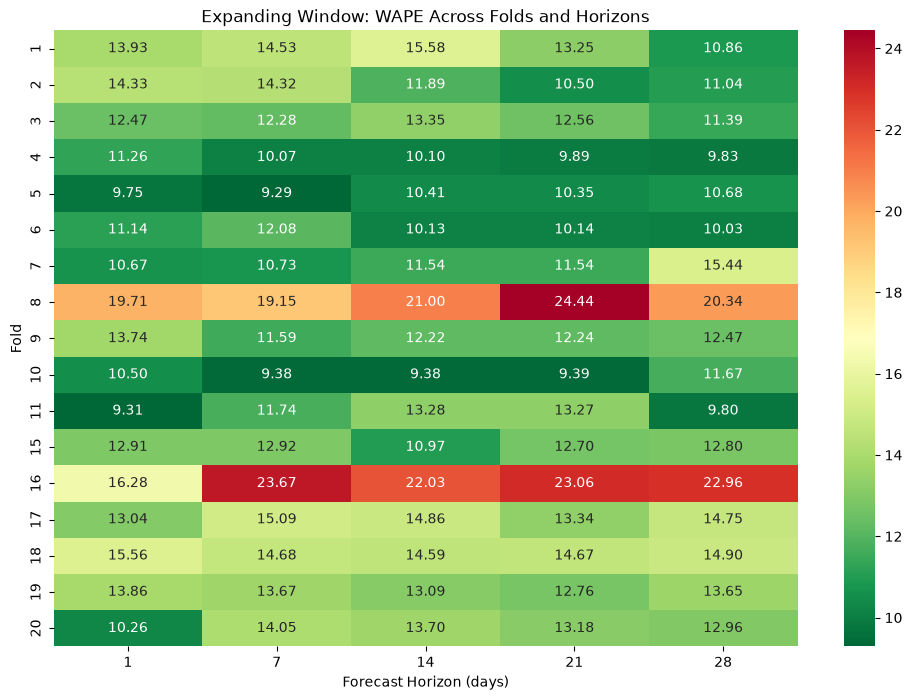

In [ ]:

import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))

sns.heatmap(expanding_wape_matrix, annot=True, fmt=".2f", cmap="RdYlGn_r")

plt.title("Expanding Window: WAPE Across Folds and Horizons")
plt.xlabel("Forecast Horizon (days)")
plt.ylabel("Fold")

plt.show()


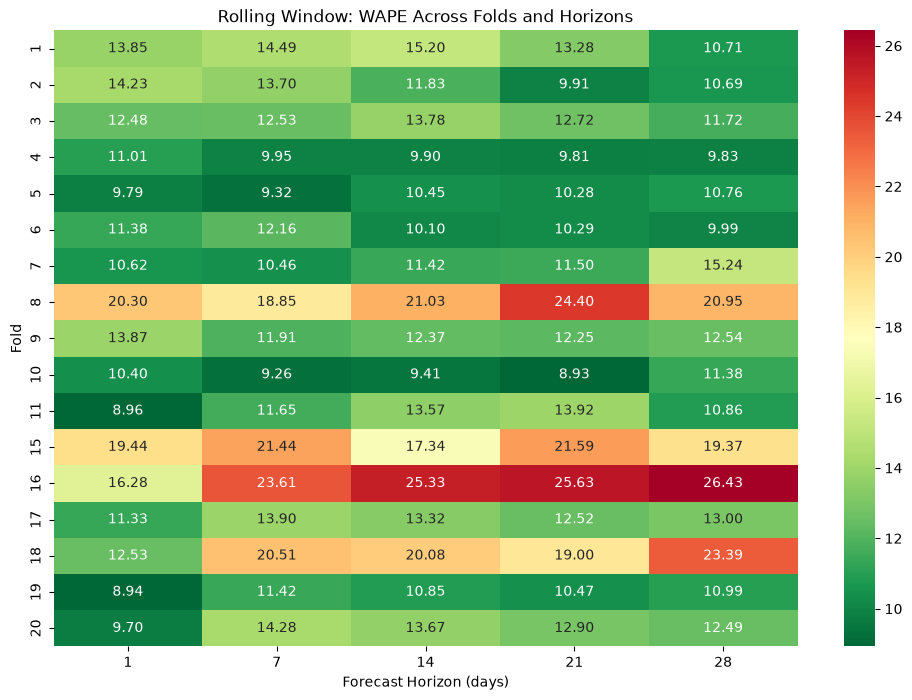

In [11]:
plt.figure(figsize=(12, 8))

sns.heatmap(rolling_wape_matrix, annot=True, fmt=".2f", cmap="RdYlGn_r")

plt.title("Rolling Window: WAPE Across Folds and Horizons")
plt.xlabel("Forecast Horizon (days)")
plt.ylabel("Fold")

plt.show()


### Summarise performance by forecast horizon

In [12]:
expanding_horizon_summary = expanding_metrics.groupby('horizon')['wape'].agg(['mean', 'median', 'std', 'min', 'max']).round(2)
rolling_horizon_summary = rolling_metrics.groupby('horizon')['wape'].agg(['mean', 'median', 'std', 'min', 'max']).round(2)


In [13]:
expanding_horizon_summary

,mean,median,std,min,max
horizon,,,,,
1,12.87,12.91,2.69,9.31,19.71
7,13.48,12.92,3.59,9.29,23.67
14,13.42,13.09,3.54,9.38,22.03
21,13.37,12.70,4.18,9.39,24.44
28,13.27,12.47,3.64,9.80,22.96


In [14]:
rolling_horizon_summary

,mean,median,std,min,max
horizon,,,,,
1,12.65,11.38,3.38,8.94,20.30
7,14.08,12.53,4.40,9.26,23.61
14,14.10,13.32,4.46,9.41,25.33
21,14.08,12.52,5.25,8.93,25.63
28,14.14,11.72,5.14,9.83,26.43


- more instability in rolling window than expanding window
- I guess historical data helps the model

### Summarise performance by fold

In [15]:
expanding_fold_summary = expanding_metrics.groupby('fold')['wape'].agg(['mean', 'median', 'std', 'min', 'max']).round(2)
rolling_fold_summary   = rolling_metrics.groupby('fold')['wape'].agg(['mean', 'median', 'std', 'min', 'max']).round(2)

In [16]:
expanding_fold_summary

,mean,median,std,min,max
fold,,,,,
1,13.63,13.93,1.77,10.86,15.58
2,12.42,11.89,1.81,10.50,14.33
3,12.41,12.47,0.70,11.39,13.35
4,10.23,10.07,0.59,9.83,11.26
5,10.10,10.35,0.57,9.29,10.68
6,10.70,10.14,0.89,10.03,12.08
7,11.98,11.54,1.98,10.67,15.44
8,20.93,20.34,2.08,19.15,24.44
9,12.45,12.24,0.79,11.59,13.74


In [17]:
rolling_fold_summary

,mean,median,std,min,max
fold,,,,,
1,13.50,13.85,1.72,10.71,15.20
2,12.07,11.83,1.87,9.91,14.23
3,12.65,12.53,0.74,11.72,13.78
4,10.10,9.90,0.51,9.81,11.01
5,10.12,10.28,0.57,9.32,10.76
6,10.78,10.29,0.95,9.99,12.16
7,11.85,11.42,1.95,10.46,15.24
8,21.10,20.95,2.04,18.85,24.40
9,12.59,12.37,0.75,11.91,13.87


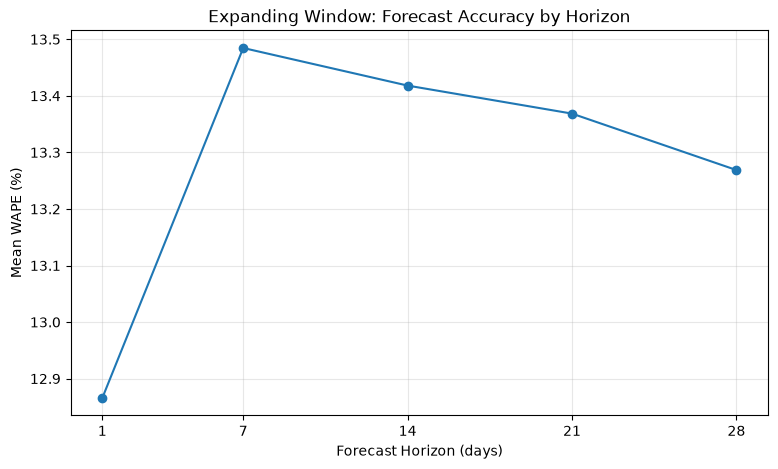

In [18]:
expanding_horizon_mean = expanding_metrics.groupby("horizon")["wape"].mean()

plt.figure(figsize=(9, 5))

plt.plot(expanding_horizon_mean.index, expanding_horizon_mean.values, marker="o")

plt.xlabel("Forecast Horizon (days)")
plt.ylabel("Mean WAPE (%)")
plt.title("Expanding Window: Forecast Accuracy by Horizon")

plt.xticks([1, 7, 14, 21, 28])
plt.grid(alpha=0.3)

plt.show()


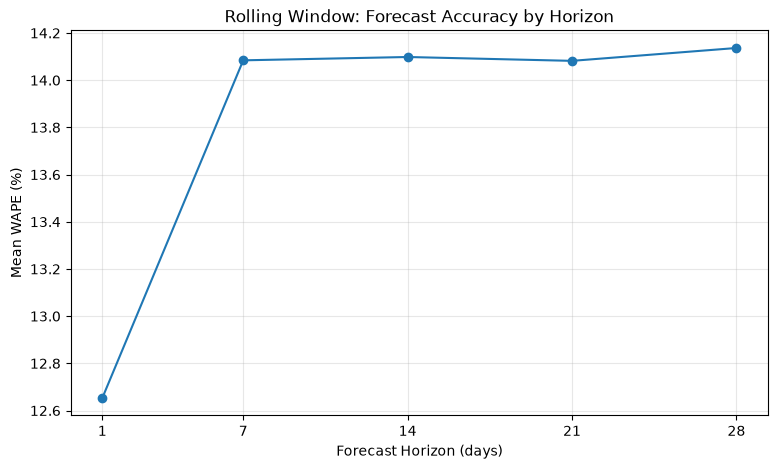

In [19]:
rolling_horizon_mean = rolling_metrics.groupby("horizon")["wape"].mean()

plt.figure(figsize=(9, 5))

plt.plot(rolling_horizon_mean.index, rolling_horizon_mean.values, marker="o")

plt.xlabel("Forecast Horizon (days)")
plt.ylabel("Mean WAPE (%)")
plt.title("Rolling Window: Forecast Accuracy by Horizon")

plt.xticks([1, 7, 14, 21, 28])
plt.grid(alpha=0.3)

plt.show()


### Comparing the 2 strategies

In [20]:
comparison = expanding_metrics.merge(
    rolling_metrics, on=["fold", "horizon"], suffixes=("_expanding", "_rolling")
)

comparison["wape_difference"] = (
    comparison["wape_rolling"] - comparison["wape_expanding"]
)


In [21]:
comparison

,fold,horizon,wape_expanding,train_rows_expanding,validation_rows_expanding,wape_rolling,train_rows_rolling,validation_rows_rolling,wape_difference
0,1,1,13.931274,1449053,79680,13.848858,1371963,79680,-0.082415
1,1,7,14.534090,1449053,79680,14.490369,1371963,79680,-0.043721
2,1,14,15.580579,1449053,79680,15.198113,1371963,79680,-0.382465
3,1,21,13.245757,1449053,79680,13.275462,1371963,79680,0.029705
4,1,28,10.864844,1449053,79680,10.705551,1371963,79680,-0.159292
...,...,...,...,...,...,...,...,...,...
80,20,1,10.259766,2345834,825,9.700193,299414,825,-0.559574
81,20,7,14.050348,2345834,825,14.278597,299414,825,0.228249
82,20,14,13.704646,2345834,825,13.670955,299414,825,-0.033691
83,20,21,13.178980,2345834,825,12.897474,299414,825,-0.281505


In [22]:
comparison.groupby("horizon")["wape_difference"].agg(
    ["mean", "median", "std", "min", "max"]
).round(2)


,mean,median,std,min,max
horizon,,,,,
1,-0.21,-0.08,2.22,-4.92,6.53
7,0.60,-0.06,2.60,-2.26,8.53
14,0.68,0.03,2.26,-2.24,6.38
21,0.71,-0.04,2.53,-2.28,8.88
28,0.87,-0.00,2.82,-2.66,8.50


WAPE difference = ROlling WAPE - Expanding WAPE

+ve values favor expanding.
Negative values favor rolling.

Three observations stand out.

**A. Expanding has a better average WAPE at horizons 7–28.**

The advantage increases as the forecast horizon increases.
- This suggests that retaining older historical information may be more useful for longer-horizon predictions.

B. The median differences are close to zero.

This is important.

For example, at 28 days:
- Mean difference: +0.87
- Median difference: approximately 0
The mean is higher than the median, suggesting that some folds where rolling performs particularly badly are pulling the average upwards.

In other words, expanding's advantage isn't necessarily consistent across individual folds.

C. The standard deviations are relatively large.

Your standard deviations range from 2.22 to 2.82 percentage points.

The differences between strategies vary considerably across folds. Sometimes rolling wins, sometimes expanding wins.

So I cannot say expanding is consistently better.

### Experiment 1: Validation strategy

**Question:** How should I evaluate a four-week forecasting model to establish whether its predictions will remain reliable when predicting future harvests?

**Approach:**
I compared expanding-window and rolling-window validation.

- Both used a 365-day initial training period.
- Validation origins were evaluated in 28-day blocks.
- The model was retrained at the beginning of each block.
- Within each block, new forecasts used the latest available historical features.
- I evaluated five forecast horizons: 1, 7, 14, 21 and 28 days.
- I used WAPE as the primary evaluation metric.

**Findings:**

Expanding-window validation produced lower average WAPE at horizons 7, 14, 21 and 28 days. Rolling-window validation performed slightly better at the 1-day horizon.

The difference between the two strategies varied considerably across validation folds. Expanding-window validation also showed lower WAPE variability across folds in the horizon-level summaries.

**Decision:**

I'll use expanding-window validation for the next experiments.

It performed better on average for most forecast horizons and was more consistent across validation periods. However, this experiment does not establish that expanding-window validation will always be better. The results are specific to this dataset, model configuration and training-window setup.